# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Faiz Akhsan
- **Email:** faizakhsansjr@gmail.com
- **ID Dicoding:** ds009b6y0551

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Berapa rata-rata jumlah penyewaan sepeda harian (`cnt`) pada tiap kondisi cuaca (Cerah, Mendung, Hujan Ringan) sepanjang 2011-2012, dan berapa persen penurunannya saat hujan ringan dibandingkan cuaca cerah, agar operator dapat menyesuaikan jumlah sepeda yang disiagakan pada hari berpotensi hujan?
- **Pertanyaan 2:** Pada jam berapa rata-rata jumlah penyewaan sepeda per jam (`cnt`) mencapai puncak tertinggi dan terendah (jam 00-23) sepanjang 2011-2012, agar distribusi armada dan jadwal perawatan sepeda dapat diatur sesuai jam sibuk?
- **Pertanyaan 3:** Berapa selisih (dalam persen) rata-rata jumlah penyewaan sepeda harian (`cnt`) antara hari kerja dan hari libur (akhir pekan + libur nasional) sepanjang 2011-2012, agar strategi promosi dan operasional dapat dibedakan untuk kedua jenis hari tersebut?
- **Pertanyaan 4:** Musim apa yang memiliki rata-rata jumlah penyewaan sepeda harian (`cnt`) tertinggi dan terendah pada tahun 2011 dibandingkan tahun 2012, agar promosi dan perawatan armada dapat dijadwalkan sesuai musim?

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style='whitegrid')

## Data Wrangling

### Gathering Data

#### Load day_df dan hour_df

In [2]:
day_df = pd.read_csv('day.csv')
hour_df = pd.read_csv('hour.csv')

print('Ukuran day_df :', day_df.shape)
print('Ukuran hour_df:', hour_df.shape)
day_df.head()

Ukuran day_df : (731, 16)
Ukuran hour_df: (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- Dataset terdiri dari dua tabel: `day_df` (data harian, 731 baris) dan `hour_df` (data per jam, 17.379 baris).
- Kedua tabel punya fitur yang hampir sama (cuaca, musim, hari kerja, `cnt`), hanya berbeda granularitas waktu. `hour_df` punya tambahan kolom `hr`.

### Assessing Data

#### Identifying tipe data dan missing value

In [4]:
day_df.info()
print('-' * 60)
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
------------------------------------------------------------
<class 'pandas.core.frame.DataFr

In [5]:
print('Missing value day_df:', day_df.isnull().sum().sum())
print('Missing value hour_df:', hour_df.isnull().sum().sum())

Missing value day_df: 0
Missing value hour_df: 0


#### Identifying duplicate data

In [6]:
print('Duplikat day_df :', day_df.duplicated().sum())
print('Duplikat hour_df:', hour_df.duplicated().sum())

Duplikat day_df : 0
Duplikat hour_df: 0


#### Identifying invalid / inconsistent value

In [7]:
# 1. cnt seharusnya = casual + registered
print('cnt != casual + registered (day) :', (day_df['cnt'] != day_df['casual'] + day_df['registered']).sum())
print('cnt != casual + registered (hour):', (hour_df['cnt'] != hour_df['casual'] + hour_df['registered']).sum())

# 2. hari libur nasional tidak boleh sekaligus hari kerja
print('holiday=1 & workingday=1 (day):', ((day_df['holiday'] == 1) & (day_df['workingday'] == 1)).sum())

# 3. rentang nilai kategori
print('Nilai unik weathersit (day) :', sorted(day_df['weathersit'].unique()))
print('Nilai unik weathersit (hour):', sorted(hour_df['weathersit'].unique()))
print('Rentang hr:', hour_df['hr'].min(), '-', hour_df['hr'].max())

cnt != casual + registered (day) : 0
cnt != casual + registered (hour): 0
holiday=1 & workingday=1 (day): 0
Nilai unik weathersit (day) : [np.int64(1), np.int64(2), np.int64(3)]
Nilai unik weathersit (hour): [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Rentang hr: 0 - 23


#### Identifying incomplete data per jam

In [8]:
# Seharusnya 731 hari x 24 jam = 17.544 baris
print('Baris seharusnya:', 731 * 24)
print('Baris di hour_df:', len(hour_df))
print('Jam yang tidak tercatat:', 731 * 24 - len(hour_df))

jam_per_hari = hour_df.groupby('dteday')['hr'].count()
print('Jumlah hari dengan jam tidak lengkap:', (jam_per_hari < 24).sum())

Baris seharusnya: 17544
Baris di hour_df: 17379
Jam yang tidak tercatat: 165
Jumlah hari dengan jam tidak lengkap: 76


#### Identifying outlier

In [9]:
def hitung_outlier(df, kolom):
    q1, q3 = df[kolom].quantile(0.25), df[kolom].quantile(0.75)
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[kolom] < batas_bawah) | (df[kolom] > batas_atas)).sum()
    return pd.Series({'batas_bawah': batas_bawah, 'batas_atas': batas_atas, 'jumlah_outlier': n})

pd.DataFrame({k: hitung_outlier(day_df, k) for k in ['cnt', 'casual', 'registered', 'windspeed', 'hum']}).T

,batas_bawah,batas_atas,jumlah_outlier
cnt,-1054.000000,10162.000000,0.0
casual,-855.250000,2266.750000,44.0
registered,-922.250000,8195.750000,0.0
windspeed,-0.012447,0.380611,13.0
hum,0.204687,1.045521,2.0


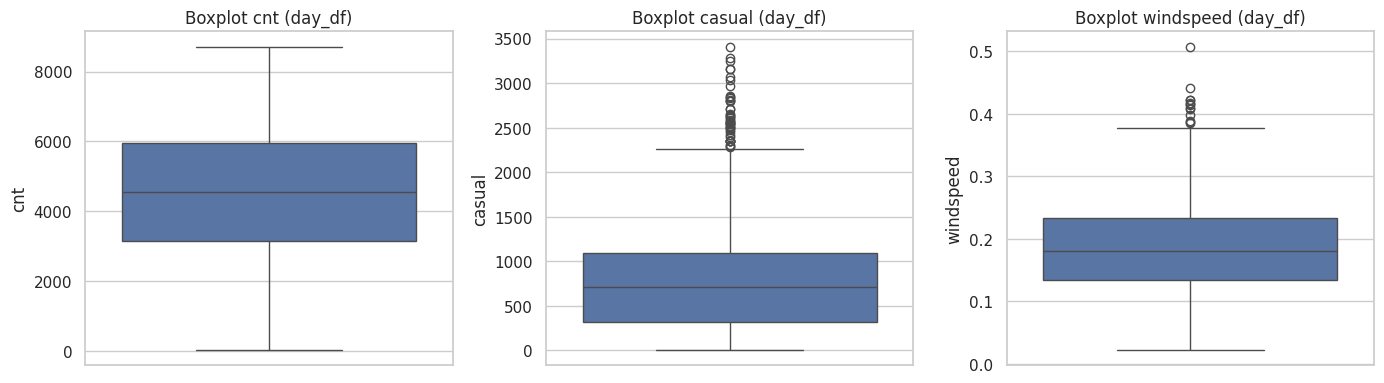

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, kol in zip(axes, ['cnt', 'casual', 'windspeed']):
    sns.boxplot(y=day_df[kol], ax=ax)
    ax.set_title(f'Boxplot {kol} (day_df)')
plt.tight_layout()
plt.show()

**Steps to Take:**
- **Tipe data tidak sesuai:** kolom `dteday` masih bertipe `object`, perlu diubah ke `datetime`.
- **Nilai kategori masih berupa kode angka:** `season`, `yr`, `workingday`, dan `weathersit` perlu di-mapping ke label yang bisa dibaca agar visualisasi dan insight mudah dipahami.
- **Data jam tidak lengkap:** ada jam yang tidak tercatat di `hour_df` (kemungkinan tidak ada transaksi). Data tidak ditambah/diisi, tetapi dicatat sebagai keterbatasan analisis karena rata-rata per jam dihitung dari jam yang tercatat saja.
- **Outlier:** terdeteksi pada `casual` dan `windspeed`. Nilainya masih wajar (misalnya hari dengan angin kencang atau event tertentu), sehingga **tidak dihapus**. Analisis `cnt` menggunakan mean dan median agar tidak bias oleh nilai ekstrem.
- **Missing value, duplikat, dan konsistensi** (`cnt = casual + registered`, `holiday` vs `workingday`) tidak bermasalah, tetap dilakukan pengecekan ulang pada tahap cleaning.

**Insight:**
- Tidak ada missing value maupun data duplikat pada kedua dataset.
- Total `cnt` konsisten dengan `casual + registered` dan tidak ada hari yang tercatat sekaligus libur nasional dan hari kerja.
- Masalah utama ada pada tipe data `dteday`, kode kategori numerik, jam yang tidak lengkap di `hour_df`, dan outlier pada `casual` serta `windspeed`.

### Cleaning Data

#### Fixing tipe data dteday

In [11]:
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

print(day_df['dteday'].dtype, hour_df['dteday'].dtype)

datetime64[ns] datetime64[ns]


#### Fixing nilai kategori (mapping label)

In [12]:
weather_map = {1: 'Cerah', 2: 'Mendung', 3: 'Hujan Ringan', 4: 'Hujan Lebat'}
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
workingday_map = {0: 'Libur', 1: 'Hari Kerja'}
year_map = {0: '2011', 1: '2012'}

# jalankan sekali saja (kolom yang sudah di-mapping akan menjadi NaN jika di-mapping ulang)
for df in [day_df, hour_df]:
    df['weathersit'] = df['weathersit'].map(weather_map)
    df['season'] = df['season'].map(season_map)
    df['workingday'] = df['workingday'].map(workingday_map)
    df['yr'] = df['yr'].map(year_map)

day_df[['season', 'yr', 'workingday', 'weathersit']].head()

,season,yr,workingday,weathersit
0,Spring,2011,Libur,Mendung
1,Spring,2011,Libur,Mendung
2,Spring,2011,Hari Kerja,Cerah
3,Spring,2011,Hari Kerja,Cerah
4,Spring,2011,Hari Kerja,Cerah


#### Fixing duplicate data

In [13]:
day_df.drop_duplicates(inplace=True)
hour_df.drop_duplicates(inplace=True)

print('Duplikat day_df :', day_df.duplicated().sum())
print('Duplikat hour_df:', hour_df.duplicated().sum())

Duplikat day_df : 0
Duplikat hour_df: 0


#### Validasi hasil cleaning

In [14]:
print('Missing value setelah mapping (day) :', day_df[['season', 'yr', 'workingday', 'weathersit']].isnull().sum().sum())
print('Missing value setelah mapping (hour):', hour_df[['season', 'yr', 'workingday', 'weathersit']].isnull().sum().sum())
print(day_df['weathersit'].value_counts())

Missing value setelah mapping (day) : 0
Missing value setelah mapping (hour): 0
weathersit
Cerah           463
Mendung         247
Hujan Ringan     21
Name: count, dtype: int64


**Insight:**
- `dteday` sudah bertipe datetime dan seluruh kode kategori sudah diganti dengan label yang mudah dibaca.
- Tidak ada nilai yang hilang akibat proses mapping.
- Kategori `Hujan Lebat` tidak muncul di `day_df` (hanya 3 jam di `hour_df`), sehingga analisis cuaca harian membandingkan tiga kondisi: Cerah, Mendung, dan Hujan Ringan.
- Outlier dipertahankan karena merupakan variasi alami data.

## Exploratory Data Analysis (EDA)

### Explore statistik deskriptif

In [15]:
day_df.describe()

,instant,dteday,mnth,holiday,weekday,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2012-01-01 00:00:00,6.519836,0.028728,2.997264,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
min,1.000000,2011-01-01 00:00:00,1.000000,0.000000,0.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2011-07-02 12:00:00,4.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,2012-01-01 00:00:00,7.000000,0.000000,3.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,2012-07-01 12:00:00,10.000000,0.000000,5.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,2012-12-31 00:00:00,12.000000,1.000000,6.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000
std,211.165812,NaN,3.451913,0.167155,2.004787,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452


In [16]:
hour_df[['hr', 'temp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']].describe()

,hr,temp,hum,windspeed,casual,registered,cnt
count,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,11.546752,0.496987,0.627229,0.190098,35.676218,153.786869,189.463088
std,6.914405,0.192556,0.192930,0.122340,49.305030,151.357286,181.387599
min,0.000000,0.020000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,6.000000,0.340000,0.480000,0.104500,4.000000,34.000000,40.000000
50%,12.000000,0.500000,0.630000,0.194000,17.000000,115.000000,142.000000
75%,18.000000,0.660000,0.780000,0.253700,48.000000,220.000000,281.000000
max,23.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


### Explore pengaruh cuaca terhadap penyewaan harian (Pertanyaan 1)

In [17]:
cuaca = day_df.groupby('weathersit')['cnt'].agg(['count', 'mean', 'median']).round(1)
cuaca = cuaca.reindex(['Cerah', 'Mendung', 'Hujan Ringan'])
cuaca['penurunan_vs_cerah_%'] = ((1 - cuaca['mean'] / cuaca.loc['Cerah', 'mean']) * 100).round(1)
cuaca

,count,mean,median,penurunan_vs_cerah_%
weathersit,,,,
Cerah,463,4876.8,4844.0,0.0
Mendung,247,4035.9,4040.0,17.2
Hujan Ringan,21,1803.3,1817.0,63.0


### Explore penyewaan per jam (Pertanyaan 2)

In [18]:
rata_jam = hour_df.groupby('hr')['cnt'].mean().round(1)

print('3 jam tertinggi:')
print(rata_jam.sort_values(ascending=False).head(3))
print('\n3 jam terendah:')
print(rata_jam.sort_values().head(3))

3 jam tertinggi:
hr
17    461.5
18    425.5
8     359.0
Name: cnt, dtype: float64

3 jam terendah:
hr
4     6.4
3    11.7
5    19.9
Name: cnt, dtype: float64


### Explore hari kerja vs hari libur (Pertanyaan 3)

In [19]:
hari = day_df.groupby('workingday')['cnt'].agg(['count', 'mean', 'median']).round(1)
display(hari)

selisih = (hari.loc['Hari Kerja', 'mean'] - hari.loc['Libur', 'mean']) / hari.loc['Libur', 'mean'] * 100
print(f'Rata-rata hari kerja lebih tinggi {selisih:.1f}% dibanding hari libur')

,count,mean,median
workingday,,,
Hari Kerja,500,4584.8,4582.0
Libur,231,4330.2,4459.0


Rata-rata hari kerja lebih tinggi 5.9% dibanding hari libur


### Explore penyewaan per musim dan tahun (Pertanyaan 4)

In [20]:
musim = day_df.groupby('season')['cnt'].agg(['count', 'mean', 'median']).round(1)
display(musim.sort_values('mean', ascending=False))

day_df.pivot_table(index='season', columns='yr', values='cnt', aggfunc='mean').round(1)

,count,mean,median
season,,,
Fall,188,5644.3,5353.5
Summer,184,4992.3,4941.5
Winter,178,4728.2,4634.5
Spring,181,2604.1,2209.0


yr,2011,2012
season,,
Fall,4464.4,6824.2
Spring,1666.7,3531.3
Summer,3775.2,6209.5
Winter,3664.5,5791.9


**Insight:**
- Rata-rata penyewaan harian turun seiring memburuknya cuaca: Cerah (sekitar 4.877) > Mendung (sekitar 4.036) > Hujan Ringan (sekitar 1.803), atau turun sekitar 63% saat hujan ringan dibanding cerah.
- Pada data per jam, penyewaan memuncak pada jam 17 (sekitar 461 per jam), disusul jam 18 dan jam 8, sedangkan terendah pada dini hari sekitar jam 4.
- Rata-rata penyewaan hari kerja (sekitar 4.585) sedikit lebih tinggi dibanding hari libur (sekitar 4.330), selisih sekitar 6%.
- Musim Fall (sekitar 5.644) tertinggi, disusul Summer, Winter, dan Spring (sekitar 2.604) terendah. Penyewaan 2012 lebih tinggi dibanding 2011 pada semua musim.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana pengaruh kondisi cuaca terhadap rata-rata penyewaan harian (2011-2012)?

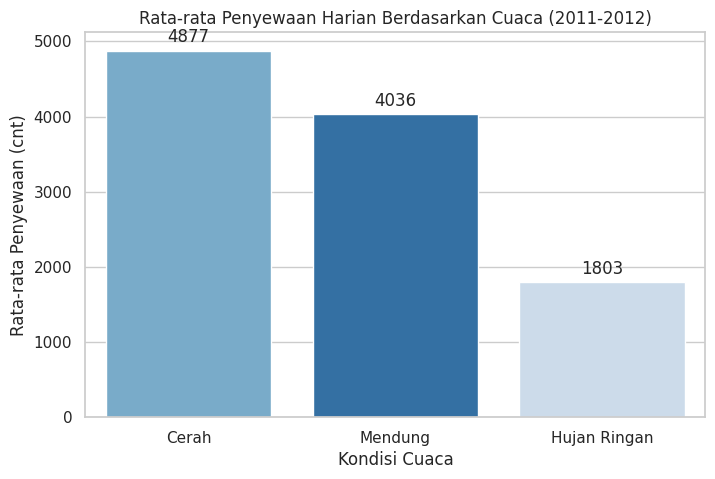

In [21]:
order_cuaca = ['Cerah', 'Mendung', 'Hujan Ringan']

plt.figure(figsize=(8, 5))
ax = sns.barplot(x='weathersit', y='cnt', hue='weathersit', data=day_df, order=order_cuaca, errorbar=None, palette='Blues_r', legend=False)
for c in ax.containers:
    ax.bar_label(c, fmt='%.0f', padding=3)
plt.title('Rata-rata Penyewaan Harian Berdasarkan Cuaca (2011-2012)')
plt.xlabel('Kondisi Cuaca')
plt.ylabel('Rata-rata Penyewaan (cnt)')
plt.show()

**Insight:**
- Penyewaan tertinggi terjadi saat cuaca cerah (sekitar 4.877 per hari), turun sekitar 17% saat mendung, dan turun sekitar 63% saat hujan ringan (sekitar 1.803 per hari).
- Hujan adalah faktor cuaca yang paling menekan permintaan, sedangkan cuaca mendung hanya menurunkan permintaan sedikit.

### Pertanyaan 2: Pada jam berapa rata-rata penyewaan tertinggi dan terendah (2011-2012)?

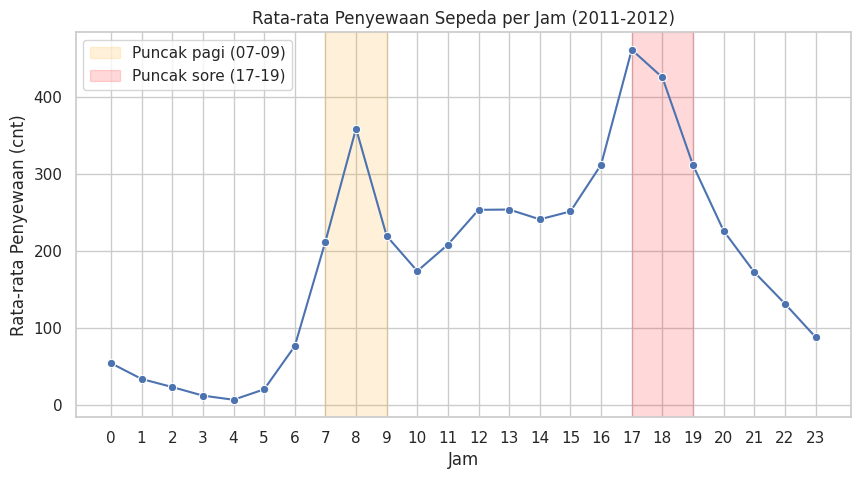

In [22]:
plt.figure(figsize=(10, 5))
sns.lineplot(x='hr', y='cnt', data=hour_df, errorbar=None, marker='o')
plt.axvspan(7, 9, color='orange', alpha=0.15, label='Puncak pagi (07-09)')
plt.axvspan(17, 19, color='red', alpha=0.15, label='Puncak sore (17-19)')
plt.xticks(range(0, 24))
plt.title('Rata-rata Penyewaan Sepeda per Jam (2011-2012)')
plt.xlabel('Jam')
plt.ylabel('Rata-rata Penyewaan (cnt)')
plt.legend()
plt.show()

**Insight:**
- Ada dua puncak: pagi sekitar jam 7-9 (puncak jam 8) dan sore sekitar jam 17-19 (puncak tertinggi jam 17), pola khas penggunaan untuk berangkat dan pulang kerja/sekolah.
- Penyewaan terendah terjadi dini hari (jam 0-5), terendah sekitar jam 4.
- Siang hari (jam 10-15) relatif stabil namun lebih rendah dari kedua puncak.

### Pertanyaan 3: Berapa selisih rata-rata penyewaan antara hari kerja dan hari libur (2011-2012)?

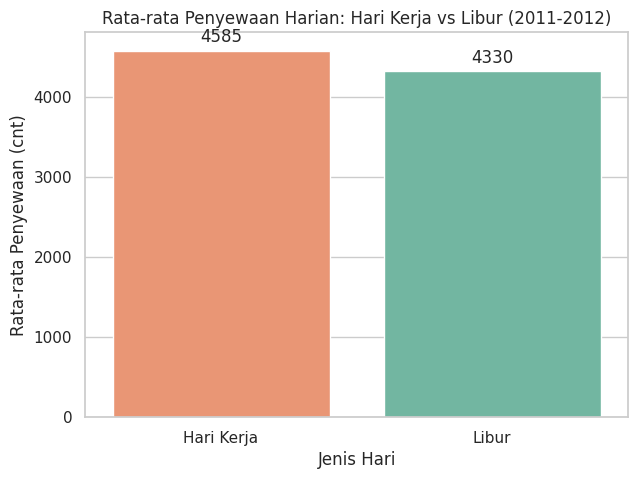

In [23]:
plt.figure(figsize=(7, 5))
ax = sns.barplot(x='workingday', y='cnt', hue='workingday', data=day_df, order=['Hari Kerja', 'Libur'], errorbar=None, palette='Set2', legend=False)
for c in ax.containers:
    ax.bar_label(c, fmt='%.0f', padding=3)
plt.title('Rata-rata Penyewaan Harian: Hari Kerja vs Libur (2011-2012)')
plt.xlabel('Jenis Hari')
plt.ylabel('Rata-rata Penyewaan (cnt)')
plt.show()

**Insight:**
- Rata-rata penyewaan hari kerja (sekitar 4.585) sedikit lebih tinggi dibanding hari libur (sekitar 4.330), selisih sekitar 6%.
- Selisih yang kecil menunjukkan permintaan sepeda cukup stabil sepanjang pekan; yang berbeda adalah pola jamnya (lihat analisis lanjutan).

### Pertanyaan 4: Musim apa yang paling tinggi dan paling rendah penyewaannya pada 2011 dibanding 2012?

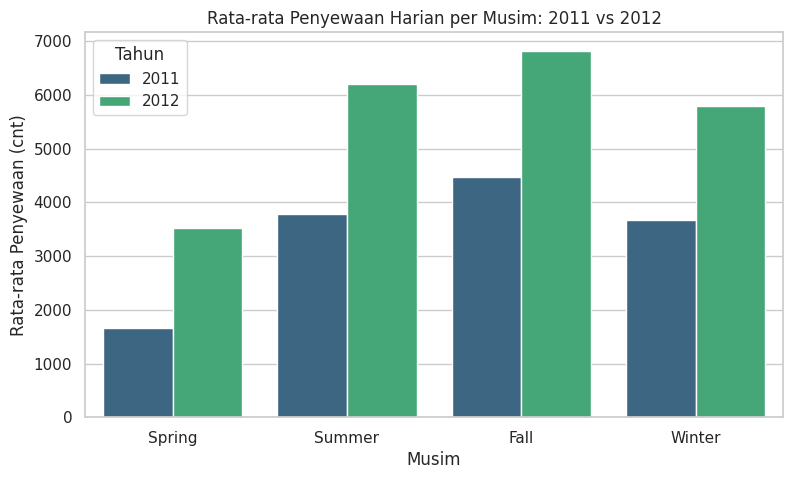

In [24]:
order_musim = ['Spring', 'Summer', 'Fall', 'Winter']

plt.figure(figsize=(9, 5))
sns.barplot(x='season', y='cnt', hue='yr', data=day_df, order=order_musim, errorbar=None, palette='viridis')
plt.title('Rata-rata Penyewaan Harian per Musim: 2011 vs 2012')
plt.xlabel('Musim')
plt.ylabel('Rata-rata Penyewaan (cnt)')
plt.legend(title='Tahun')
plt.show()

**Insight:**
- Pola musim sama di kedua tahun: Fall tertinggi, Spring terendah.
- Penyewaan 2012 lebih tinggi dibanding 2011 pada semua musim, menandakan pertumbuhan pengguna.
- Spring konsisten terendah, sehingga menjadi musim dengan potensi peningkatan terbesar lewat promosi.

## Analisis Lanjutan (Opsional)

### Pola jam pada hari kerja vs hari libur

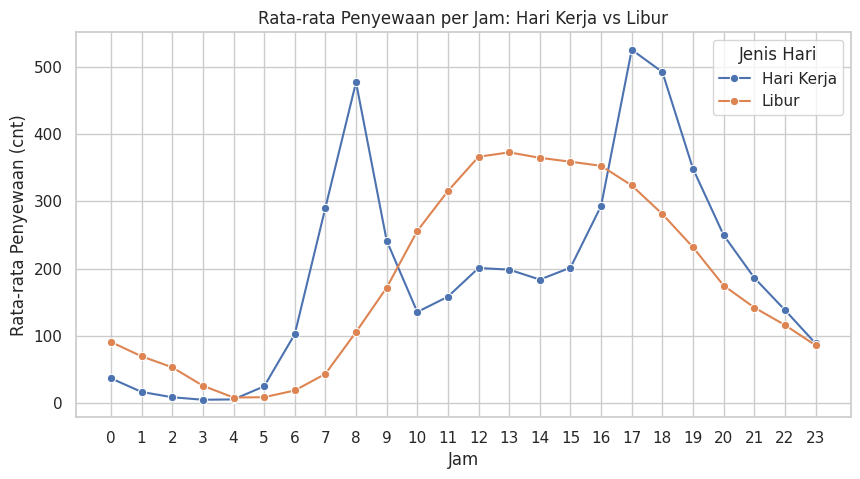

In [25]:
plt.figure(figsize=(10, 5))
sns.lineplot(x='hr', y='cnt', hue='workingday', data=hour_df, errorbar=None, marker='o', hue_order=['Hari Kerja', 'Libur'])
plt.xticks(range(0, 24))
plt.title('Rata-rata Penyewaan per Jam: Hari Kerja vs Libur')
plt.xlabel('Jam')
plt.ylabel('Rata-rata Penyewaan (cnt)')
plt.legend(title='Jenis Hari')
plt.show()

**Insight:**
- Hari kerja memiliki dua puncak tajam (jam 8 dan jam 17-18, pola komuter), sedangkan hari libur lebih landai dengan puncak di tengah hari sekitar jam 12-14 (pola rekreasi).

### Binning: kelompok jumlah penyewaan harian

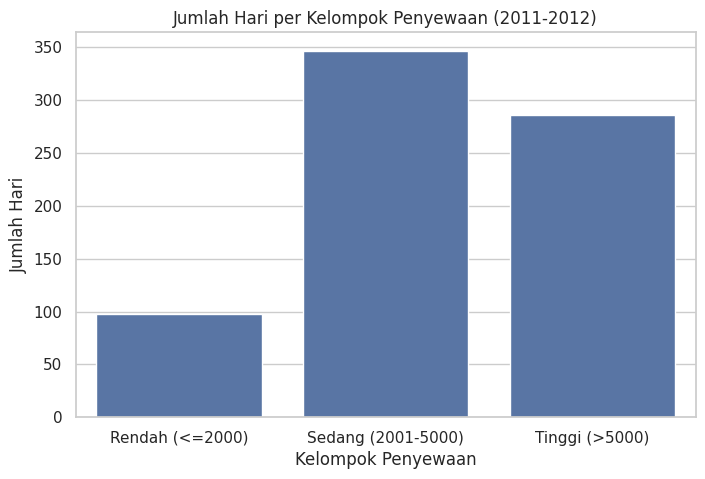

In [26]:
day_df['rental_group'] = pd.cut(
    day_df['cnt'],
    bins=[0, 2000, 5000, 10000],
    labels=['Rendah (<=2000)', 'Sedang (2001-5000)', 'Tinggi (>5000)']
)

plt.figure(figsize=(8, 5))
sns.countplot(x='rental_group', data=day_df)
plt.title('Jumlah Hari per Kelompok Penyewaan (2011-2012)')
plt.xlabel('Kelompok Penyewaan')
plt.ylabel('Jumlah Hari')
plt.show()

**Insight:**
- Hari dapat dikelompokkan menjadi Rendah (98 hari), Sedang (347 hari), dan Tinggi (286 hari); kelompok Tinggi menandai hari dengan permintaan puncak yang membutuhkan armada maksimal.

### Binning: kelompok waktu dalam sehari

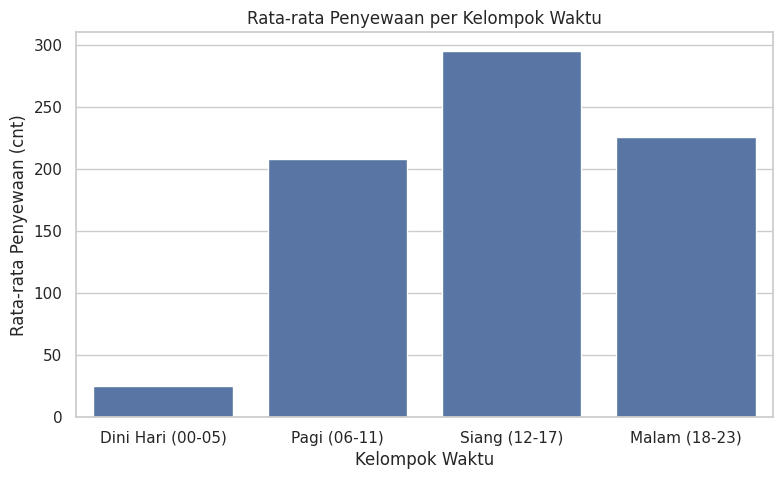

In [27]:
hour_df['time_group'] = pd.cut(
    hour_df['hr'],
    bins=[0, 6, 12, 18, 24],
    labels=['Dini Hari (00-05)', 'Pagi (06-11)', 'Siang (12-17)', 'Malam (18-23)'],
    right=False
)

plt.figure(figsize=(9, 5))
sns.barplot(x='time_group', y='cnt', data=hour_df, errorbar=None)
plt.title('Rata-rata Penyewaan per Kelompok Waktu')
plt.xlabel('Kelompok Waktu')
plt.ylabel('Rata-rata Penyewaan (cnt)')
plt.show()

**Insight:**
- Kelompok Siang (12-17) memiliki rata-rata tertinggi, sedangkan Dini Hari (00-05) paling rendah.
- Pengelompokan ini menyembunyikan puncak pagi jam 7-9, sehingga untuk keputusan operasional grafik per jam (Pertanyaan 2) lebih tepat digunakan.

### Menyiapkan data untuk dashboard (main_data.csv)

In [28]:
day = pd.read_csv('day.csv')
hour = pd.read_csv('hour.csv')

day['dteday'] = pd.to_datetime(day['dteday'])
hour['dteday'] = pd.to_datetime(hour['dteday'])

day_selected = day[['dteday', 'weathersit', 'season']]

df = pd.merge(hour, day_selected, on='dteday', how='left')
df.to_csv('main_data.csv', index=False)

In [29]:
from google.colab import files
files.download('main_data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Insight:**
- Data gabungan harian dan per jam disimpan sebagai `main_data.csv` untuk digunakan pada dashboard Streamlit.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Cuaca sangat memengaruhi penyewaan. Rata-rata penyewaan harian saat cerah sekitar 4.877, mendung sekitar 4.036 (turun sekitar 17%), dan hujan ringan sekitar 1.803 (turun sekitar 63%) sepanjang 2011-2012.
- **Conclusion pertanyaan 2:** Penyewaan per jam memuncak pada jam 17 (sekitar 461 per jam), disusul jam 18 dan jam 8, dengan dua puncak pada pukul 07-09 dan 17-19. Penyewaan terendah terjadi dini hari (jam 0-5), terendah sekitar jam 4.
- **Conclusion pertanyaan 3:** Rata-rata penyewaan hari kerja (sekitar 4.585) lebih tinggi sekitar 6% dibanding hari libur (sekitar 4.330). Hari kerja didominasi pola komuter (puncak pagi dan sore), sedangkan hari libur lebih merata dengan puncak di siang hari.
- **Conclusion pertanyaan 4:** Fall adalah musim dengan penyewaan tertinggi (sekitar 5.644 per hari) dan Spring terendah (sekitar 2.604 per hari). Pola ini sama di 2011 dan 2012, dengan penyewaan 2012 lebih tinggi di semua musim.

**Rekomendasi Action Item:**
- **Armada per jam:** siapkan dan redistribusi sepeda di stasiun ramai sebelum jam sibuk 07-09 dan 16-19 pada hari kerja, serta jadwalkan perawatan dan pengecekan sepeda pada dini hari (00-05) saat permintaan paling rendah.
- **Cuaca:** gunakan prakiraan cuaca untuk menyesuaikan jumlah sepeda yang disiagakan; saat hujan, kurangi armada aktif dan manfaatkan untuk perawatan, sedangkan saat cerah tambah armada. Pertimbangkan promo atau insentif pada hari mendung untuk menjaga permintaan.
- **Musim:** fokuskan kampanye promosi pada musim Spring (penyewaan terendah) dan siapkan armada maksimal pada Summer dan Fall; jadwalkan perawatan besar pada musim dengan permintaan rendah.
- **Hari libur:** buat paket promosi rekreasi (misalnya tarif akhir pekan atau rute wisata) untuk mengangkat penyewaan hari libur yang sekitar 6% lebih rendah dibanding hari kerja.